# Ploynomial Regression

Polynomial regression is a statistical technique that uses an nth degree polynomial to model the relationship between variables.

    Y = bo + b1X1 + b2X1^2 + b3X1^3 +...... + bnX1^n

---

### Why Polynomial and not Simple Linear

A simple linear regression model assumes a straight-line relationship between features, which fails when the actual relationship is non-linear. This leads to underfitting, where the model cannot capture the true pattern in the data, resulting in poor predictions.

Polynomial regression solves this by introducing higher-degree terms, allowing the model to fit curved relationships more accurately

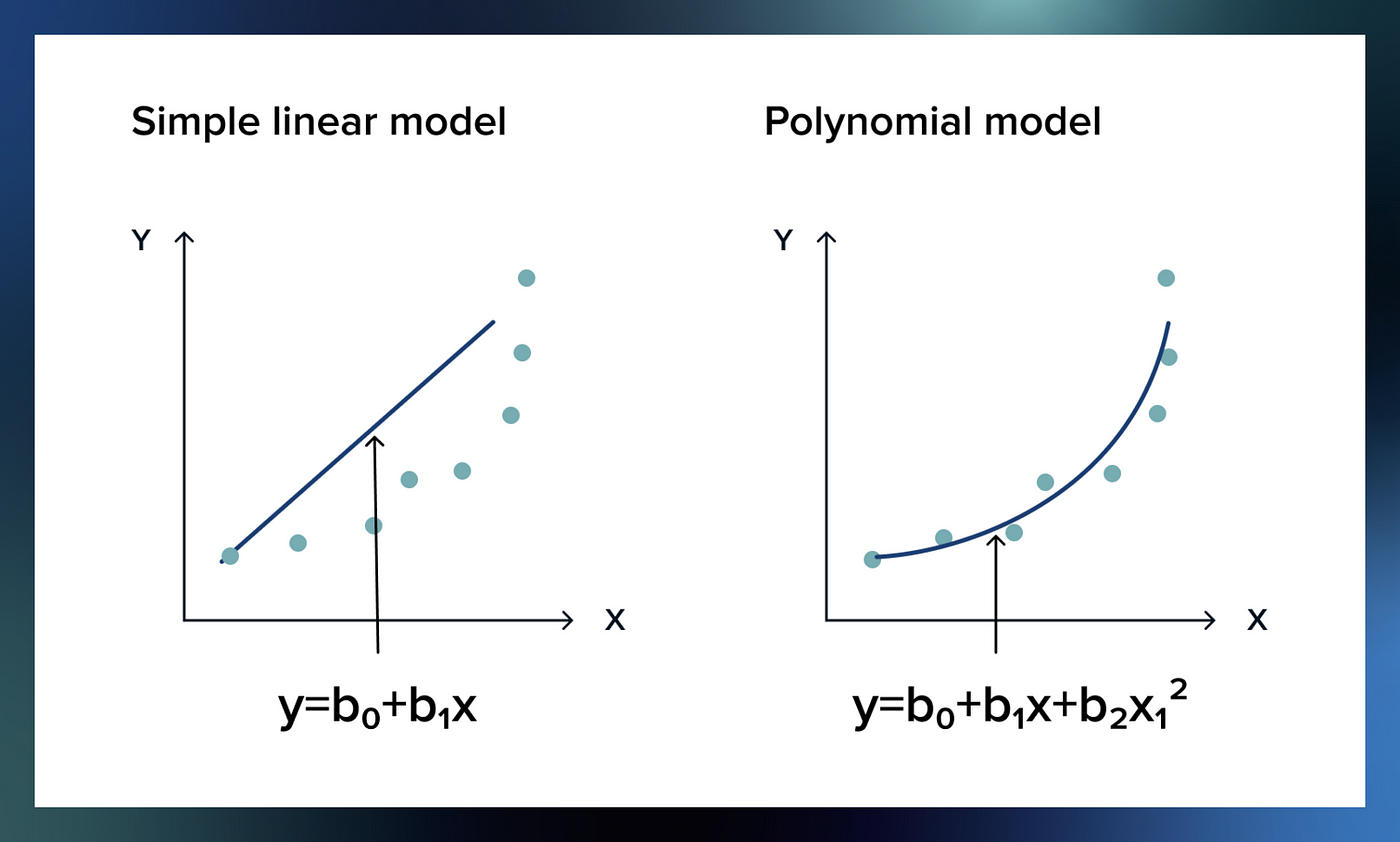
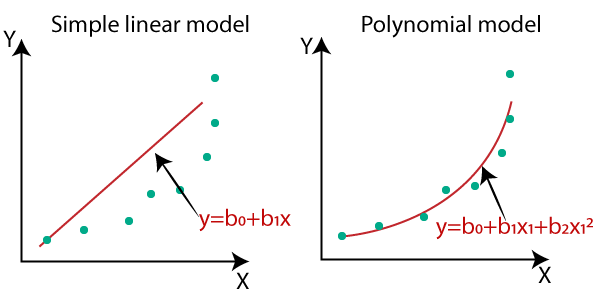

---

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#### Generate the dataset

In [2]:
# # Set seed for reproducibility
# np.random.seed(42)

# # Generate 'Level' feature (random integers from 1 to 100)
# levels = np.random.randint(1, 101, size=500)  # 500 data points

# # Generate 'Salary' with polynomial + exponential pattern
# # salaries = 500 * levels**2 + 10000 * levels + np.exp(levels / 10) + np.random.randint(-20000, 20000, size=len(levels))
# salaries = 500 * levels**2 + 10000 * levels + np.exp(levels / 10) 
# salaries += np.random.normal(0, 50000, size=len(levels))  # Add Gaussian noise

# # Create DataFrame
# df = pd.DataFrame({'Level': levels, 'Salary': salaries})

# # Save to CSV
# df.to_csv(r'../datasets/polynomial_exponential_salary_data.csv', index=False)

# print("Dataset saved as '/polynomial_exponential_salary_data.csv'")


In [3]:
df = pd.read_csv("../datasets/polynomial_exponential_salary_data.csv")
df.head(3)

,Level,Salary
0,52,1.835644e+06
1,93,5.201442e+06
2,15,2.506349e+05


In [4]:
df.isnull().sum()

Level     0
Salary    0
dtype: int64

In [5]:
df.shape

(500, 2)

#### Plot the data

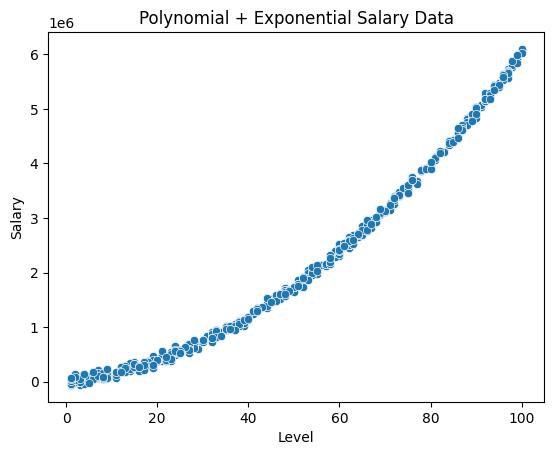

In [6]:
sns.scatterplot(x=df['Level'], y=df['Salary'])
plt.title("Polynomial + Exponential Salary Data")
plt.show()

#### Checking Corelation

In [7]:
df.corr()

,Level,Salary
Level,1.000000,0.975235
Salary,0.975235,1.000000


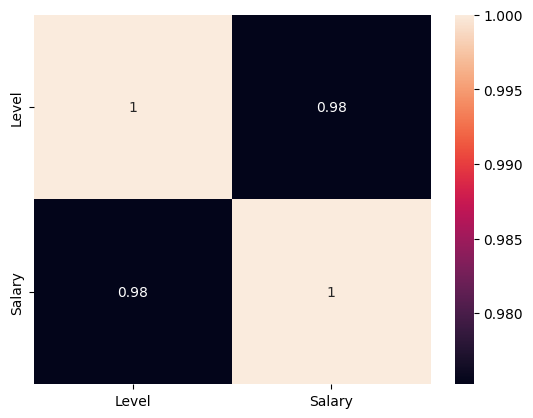

In [8]:
sns.heatmap(data=df.corr(), annot=True)
plt.show()

In [9]:
x = df[['Level']]
y = df['Salary']

x.ndim, y.ndim

(2, 1)

#### Converting Data into Polynomial Feature

In [10]:
from sklearn.preprocessing import PolynomialFeatures

In [11]:
pf = PolynomialFeatures(degree=2)
pf.fit(x)
pf.transform(x)

array([[1.000e+00, 5.200e+01, 2.704e+03],
       [1.000e+00, 9.300e+01, 8.649e+03],
       [1.000e+00, 1.500e+01, 2.250e+02],
       ...,
       [1.000e+00, 2.200e+01, 4.840e+02],
       [1.000e+00, 9.300e+01, 8.649e+03],
       [1.000e+00, 6.700e+01, 4.489e+03]])

In [12]:
x = pf.transform(x)

#### Train the model

In [13]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [14]:
lr = LinearRegression()
lr.fit(x_train, y_train)

LinearRegression()

In [15]:
lr.score(x_test, y_test)

0.9994064307942131

In [16]:
lr.predict(x_test)

array([  47929.15862573,   77348.68491434,  524108.57481684,
       1298439.94066839,  706342.37098441, 1514998.59277663,
       1932900.62231186,  667873.56560307, 4099910.046672  ,
       3154054.25826215, 3568823.3614306 , 2542996.8930363 ,
        129060.64740162, 2542996.8930363 ,   77348.68491434,
        338791.780855  , 2615840.48293082, 5065936.36798768,
       5271273.90913782, 1629344.05727426, 4864642.91913321,
         11382.54224719,  490694.88480507, 5694081.2683251 ,
       1996645.00454113, 5586862.8939174 ,  458292.21786722,
       4765512.72931685, 4864642.91913321,   93574.98266951,
       5168099.62702579,  311444.22928673, 2261732.76419738,
       4570285.41890588,  259782.19537195,  110812.30349861,
       1146636.69386334, 1747733.61406755,  827814.92557196,
       1404697.22057468,  827814.92557196, 2542996.8930363 ,
       2261732.76419738,  745822.19943968, 5168099.62702579,
       5271273.90913782, 1870167.2631565 , 6021802.52999168,
        558533.28790252,

In [17]:
lr.coef_

array([   0.        , 9654.64777472,  505.51153696])

In [18]:
lr.intercept_

1222.382935514208

In [19]:
# y = m0 + m1x1 + m2x1^2 + c

# 52	1.835644e+06

y_ans = 0 + (9654.64777472 * 52) + (505.51153696 * (52**2)) + 1222.382935514208
y_ans


1870167.2631607943

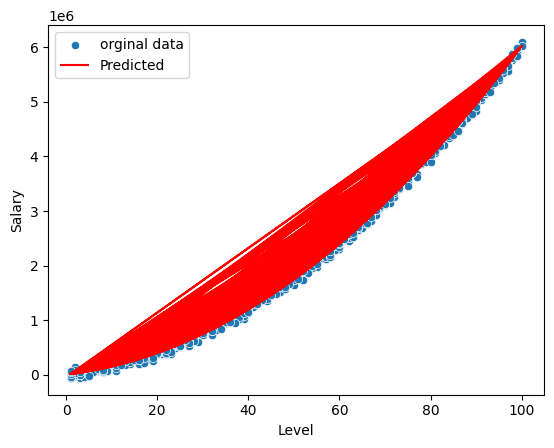

In [20]:
y_predict = lr.predict(x)

sns.scatterplot(x=df['Level'], y=df['Salary'])

# Plot the prediction line
plt.plot(df['Level'], y_predict, color="red") 

plt.legend(["orginal data", "Predicted"])
plt.show()

In [21]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

y_actual = y

# Calculate error metrics
r2 = r2_score(y_actual, y_predict)
mse = mean_squared_error(y_actual, y_predict)
rmse = np.sqrt(mse)

# Print results
print(f"R² Score: {r2:.4f}")   # Closer to 1 is better
print(f"MSE: {mse:.4f}")       # Lower is better
print(f"RMSE: {rmse:.4f}")     # Lower is better

R² Score: 0.9992
MSE: 2664415669.3052
RMSE: 51617.9782


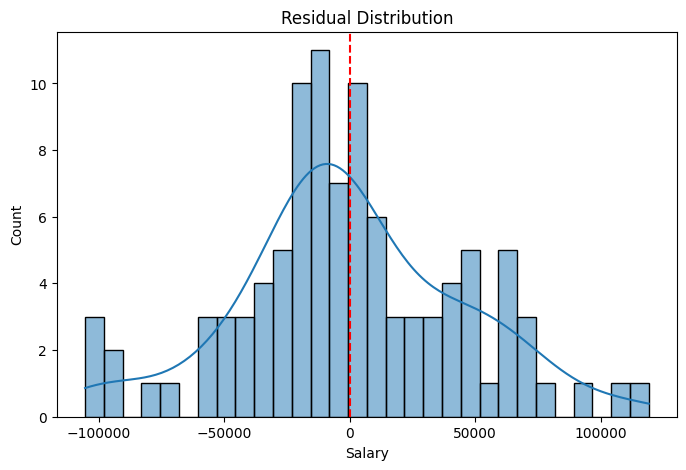

In [22]:
residuals = y_test - lr.predict(x_test)

plt.figure(figsize=(8,5))
sns.histplot(residuals, bins=30, kde=True)
plt.axvline(0, color='red', linestyle='--')
plt.title("Residual Distribution")
plt.show()


---

## When Deploying

In [23]:
input_var = 52

In [24]:
test = pf.transform([[input_var]])

c:\Users\atkar\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


In [25]:
lr.predict(test)

array([1870167.2631565])

---